# 실습 5-2 : SHAP Value

#### **<실습 내용>**

1. SHAP - 회귀 모델 (Regression)
- TreeExplainer를 사용한 SHAP 분석
- Summary Plot / Force Plot / Dependence Plot

3. SHAP - 분류 모델 (Classification)
- TreeExplainer를 사용한 SHAP 분석
- Summary Plot / Force Plot / Dependence Plot

## 분석 준비

### 주요 라이브러리 호출

In [1]:
!pip install shap


   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, f1_score
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

import shap

---

## 1) SHAP - 회귀 모델

In [3]:
# 회귀 성능 평가 함수
def get_regscore(true, pred):
    print("MSE       : %.3f" % mean_squared_error(true, pred))
    print("RMSE      : %.3f" % np.sqrt(mean_squared_error(true, pred)))
    print("MAE       : %.3f" % mean_absolute_error(true, pred))
    print("R-squared : %.3f" % r2_score(true, pred))

### 1-1) 데이터 및 모델 준비

In [4]:
Regression = pd.read_csv("dataset/day5-2_reg_data.csv")
Regression

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X50,X51,X52,X53,X54,X55,X56,X57,X58,y
0,0.40420,0.39615,0.34470,0.39535,0.44180,0.38830,0.36245,0.34480,0.32475,0.38020,...,0.39200,0.34985,0.37980,0.42355,0.38990,0.40890,0.41720,0.37765,0.36190,48.272178
1,0.47115,0.35280,0.29120,0.30190,0.54875,0.40430,0.42125,0.32620,0.35280,0.43115,...,0.32080,0.35185,0.35570,0.38400,0.44375,0.25945,0.55030,0.43205,0.31395,49.767621
2,0.31185,0.35220,0.41940,0.38370,0.30015,0.32555,0.39790,0.44730,0.55625,0.60885,...,0.36105,0.36230,0.30455,0.26945,0.49770,0.37425,0.27800,0.41980,0.37620,45.512356
3,0.43900,0.38300,0.38830,0.33920,0.40740,0.40650,0.45455,0.40565,0.41915,0.33565,...,0.33715,0.46605,0.45040,0.37150,0.37625,0.28595,0.45195,0.40570,0.39885,55.646432
4,0.38005,0.42835,0.53105,0.39145,0.31755,0.40365,0.33230,0.48530,0.44295,0.37615,...,0.43555,0.30330,0.26910,0.35155,0.42230,0.43660,0.35875,0.43605,0.46260,47.703096
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
236,0.40675,0.37110,0.29385,0.37125,0.43345,0.32380,0.40365,0.32200,0.35655,0.50940,...,0.31965,0.32385,0.37480,0.37240,0.46065,0.33660,0.40075,0.37875,0.30040,44.683854
237,0.37940,0.36660,0.39205,0.42100,0.37860,0.42690,0.39580,0.39240,0.39080,0.35705,...,0.43260,0.40485,0.36410,0.45070,0.37270,0.45270,0.36685,0.39055,0.40395,47.907255
238,0.35150,0.35285,0.24365,0.40190,0.50055,0.37125,0.36820,0.28830,0.34130,0.48590,...,0.38300,0.38705,0.41305,0.40750,0.39510,0.40895,0.40825,0.35865,0.30240,45.900853
239,0.30580,0.46180,0.50870,0.43220,0.38695,0.43260,0.24155,0.45805,0.38565,0.29875,...,0.51305,0.36490,0.35580,0.36160,0.31170,0.53040,0.36960,0.38475,0.49090,51.418961


In [5]:
X_reg = Regression.drop(["y"], axis=1) # 입력변수
Y_reg = Regression["y"] # 출력변수

X_train_reg, X_test_reg, Y_train_reg, Y_test_reg = train_test_split(X_reg, Y_reg, test_size=0.2, random_state=42) # 학습/테스트 데이터 분할

In [6]:
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=0) # RandomForest로 모델 학습
rf_reg.fit(X_train_reg, Y_train_reg)
Y_pred_reg = rf_reg.predict(X_test_reg)
get_regscore(Y_test_reg, Y_pred_reg)

MSE       : 6.592
RMSE      : 2.568
MAE       : 1.991
R-squared : 0.558


### 2-2) SHAP 분석

In [7]:
# rf_reg 모델을 해석하기 위한 SHAP 설명자 생성
explainer_reg = shap.TreeExplainer(rf_reg)

# 학습 데이터(X_train_reg)에 대한 SHAP value 계산
# 각 feature가 예측값에 기여하는 정도를 나타냄
shap_values_reg = explainer_reg.shap_values(X_train_reg)

#### Summary Plot (Bar)
- 막대가 길수록 예측에 영향을 많이 주는 변수라는 뜻임

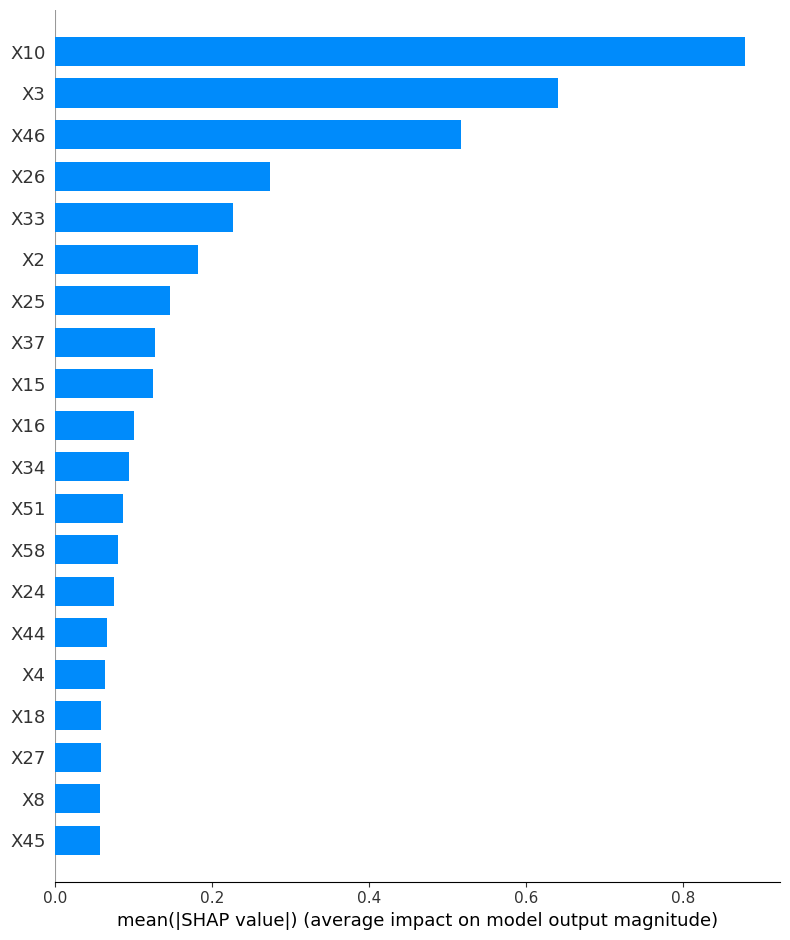

In [8]:
shap.summary_plot(shap_values_reg, X_train_reg, plot_type='bar')

#### Summary Plot (Scatter)
- 오른쪽에 점이 몰려있으면 예측값을 올리는 변수, 왼쪽에 몰려있으면 예측값을 낮추는 변수임

> - 빨간색: 높은 변수 값
> - 파란색: 낮은 변수 값

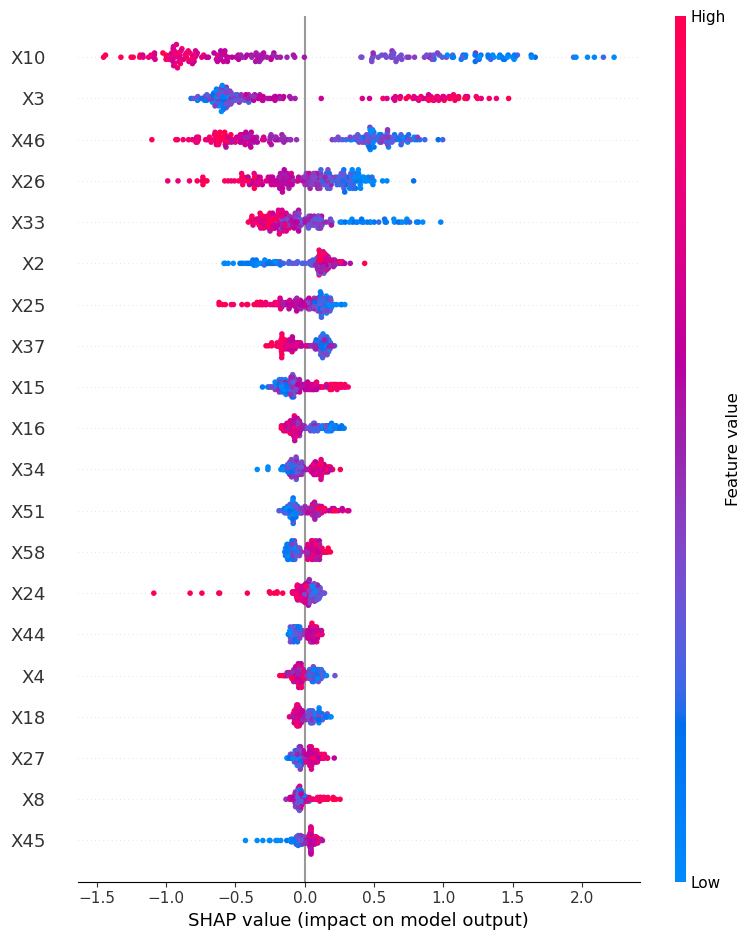

In [9]:
shap.summary_plot(shap_values_reg, X_train_reg)

#### Force Plot (개별 데이터)
- 데이터 하나를 뽑아서 어떤 변수가 예측값을 올렸고 내렸는지 화살표로 보여주는 그래프임

In [10]:
base_value_reg = explainer_reg.expected_value
print(base_value_reg)

[49.74460342]


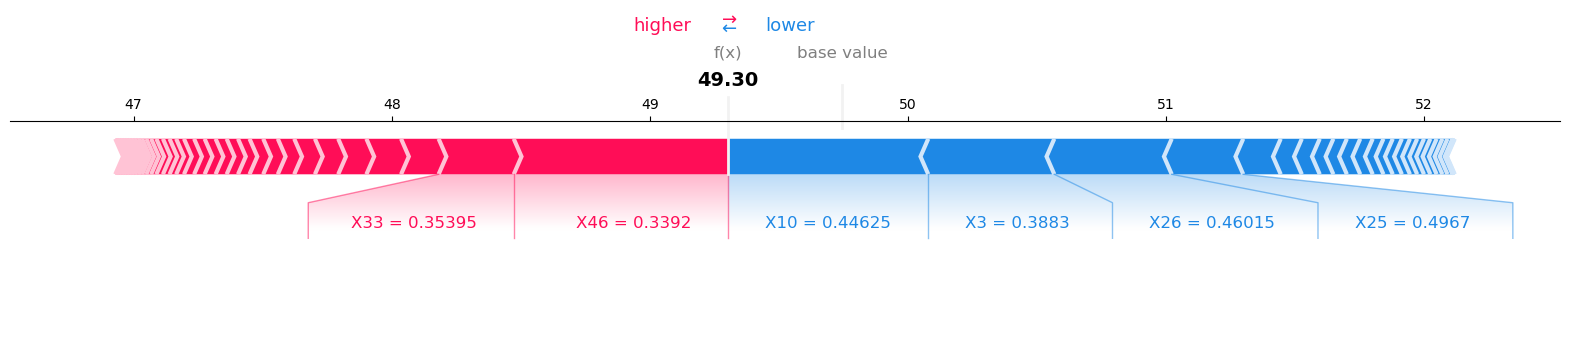

In [11]:
# 첫 번째 데이터(index 0)의 예측 결과를 force plot으로 시각화
# expected_value: 전체 데이터의 평균 예측값 (기준선)
# shap_values_reg[0]: 이 데이터의 각 feature별 SHAP value 
# X_train_reg.iloc[0]: 실제 feature 값들 (그래프에 표시용)

shap.force_plot(
    explainer_reg.expected_value,
    shap_values_reg[0],
    X_train_reg.iloc[0],
    matplotlib=True
)

#### Dependence Plot
- 변수 값이 변할 때 SHAP 값(영향력)이 같이 어떻게 움직이는지 보여주는 그래프임

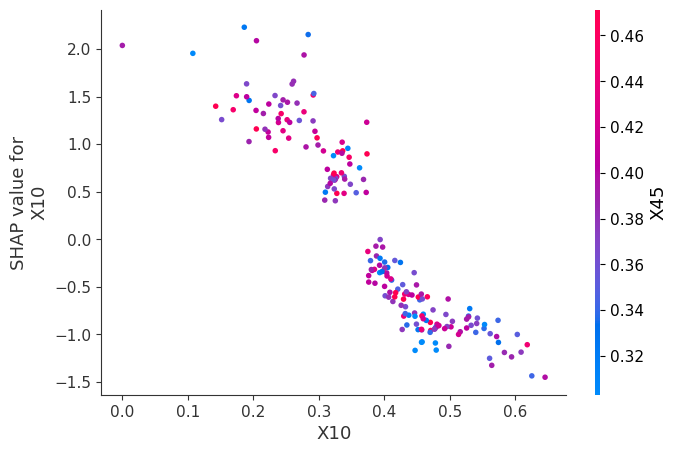

In [12]:
# "X10" feature 값에 따라 SHAP value가 어떻게 변하는지 시각화
# x축: X10의 실제 값, y축: X10의 SHAP value (예측에 미친 영향)
# 자동으로 X10과 가장 상호작용이 큰 feature를 색상으로 표시

shap.dependence_plot(
    "X10",
    shap_values_reg,
    X_train_reg
)

---

## 3) SHAP - 분류 모델

In [13]:
# 분류 성능 평가 함수
def get_classscore(real, pred):
    print("Accuracy  : %.3f" % accuracy_score(real, pred))
    print("Precision : %.3f" % precision_score(real, pred))
    print("Recall    : %.3f" % recall_score(real, pred))
    print("F1-score  : %.3f" % f1_score(real, pred))
    print()
    print("혼동행렬")
    print(confusion_matrix(real, pred))

### 3-1) 데이터 및 모델 준비

In [14]:
Classification = pd.read_csv("dataset/day5-2_cls_data.csv")
Classification

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X466,X467,X468,X469,X470,X471,X472,X473,X474,Y
0,0.457896,0.530189,0.276976,0.359864,0.193059,0.322190,0.706897,0.553781,0.653894,0.375204,...,0.246376,0.711806,0.008532,0.013672,0.008467,0.402240,0.238811,0.274876,0.210238,-1
1,0.607100,0.341478,0.518992,0.395300,0.042071,0.469654,0.750000,0.542031,0.447466,0.189233,...,0.523785,0.760417,0.030930,0.033203,0.029759,0.210356,0.309339,0.328358,0.439175,-1
2,0.360781,0.369653,0.341039,0.021697,0.181737,0.528684,0.491379,0.516722,0.300371,0.376835,...,0.185769,0.659722,0.005333,0.003906,0.005311,0.381877,0.208171,0.208955,0.155761,-1
3,0.460910,0.413500,0.535685,0.302794,0.242326,0.408966,0.646552,0.561615,0.415328,0.313214,...,0.246376,0.000000,1.000000,1.000000,1.000000,0.381877,0.208171,0.208955,0.155761,-1
4,0.263068,0.279821,0.535685,0.302794,0.242326,0.408966,0.646552,0.638747,0.660074,0.520392,...,0.110711,0.517361,0.023677,0.022461,0.023447,0.608414,0.212062,0.268657,0.092827,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,0.360022,0.396033,0.382803,0.070771,0.143308,0.920884,0.586207,0.636336,0.337454,0.432300,...,0.000000,0.597222,0.016212,0.013672,0.015997,0.045307,0.147860,0.171642,0.000000,1
250,0.508628,0.437628,0.192378,0.061866,0.168425,0.481919,0.715517,0.270563,0.407911,0.336052,...,0.132582,0.975694,0.017065,0.015625,0.016114,0.543689,0.227626,0.320896,0.111165,1
251,0.275930,0.364365,0.302236,0.376615,0.485135,0.627270,0.594828,0.435673,0.420272,0.367047,...,0.246376,0.586806,0.008532,0.015625,0.008613,0.343042,0.151751,0.164179,0.143012,1
252,0.785179,0.271804,0.400189,0.457851,0.229526,0.244320,0.396552,0.875565,0.110012,0.337684,...,0.221768,0.767361,0.024317,0.019531,0.023461,0.509709,0.398833,0.440299,0.185945,1


In [15]:
X_cls = Classification.drop(["Y"], axis=1) # 입력변수
Y_cls = Classification["Y"] # 출력변수

X_train_cls, X_test_cls, Y_train_cls, Y_test_cls = train_test_split(
    X_cls, Y_cls, test_size=0.2, random_state=123, stratify=Y_cls)

rf_cls = RandomForestClassifier(n_estimators=100, random_state=0)
rf_cls.fit(X_train_cls, Y_train_cls)
Y_pred_cls = rf_cls.predict(X_test_cls)
get_classscore(Y_test_cls, Y_pred_cls)

Accuracy  : 0.863
Precision : 0.938
Recall    : 0.714
F1-score  : 0.811

혼동행렬
[[29  1]
 [ 6 15]]


### 3-2) SHAP 분석

In [16]:
explainer_cls = shap.TreeExplainer(rf_cls)
shap_values_cls = explainer_cls.shap_values(X_train_cls)

#### Summary Plot (Bar)

> 분류 모델의 경우 `shap_values_cls`는 (샘플 수, 변수 수, 클래스 수) 형태의 3차원 배열임
> - `shap_values_cls[:, :, 0]`: 클래스 -1에 대한 SHAP
> - `shap_values_cls[:, :, 1]`: 클래스 1에 대한 SHAP

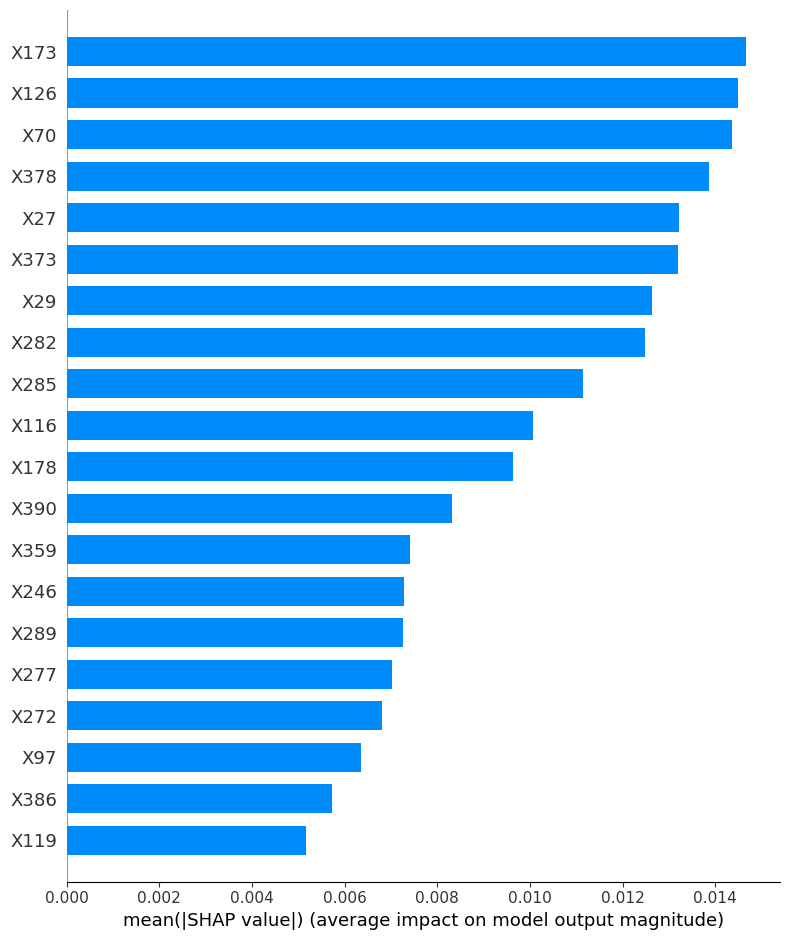

In [17]:
shap.summary_plot(shap_values_cls[:, :, 0], X_train_cls, plot_type='bar')  # 클래스 -1 기준

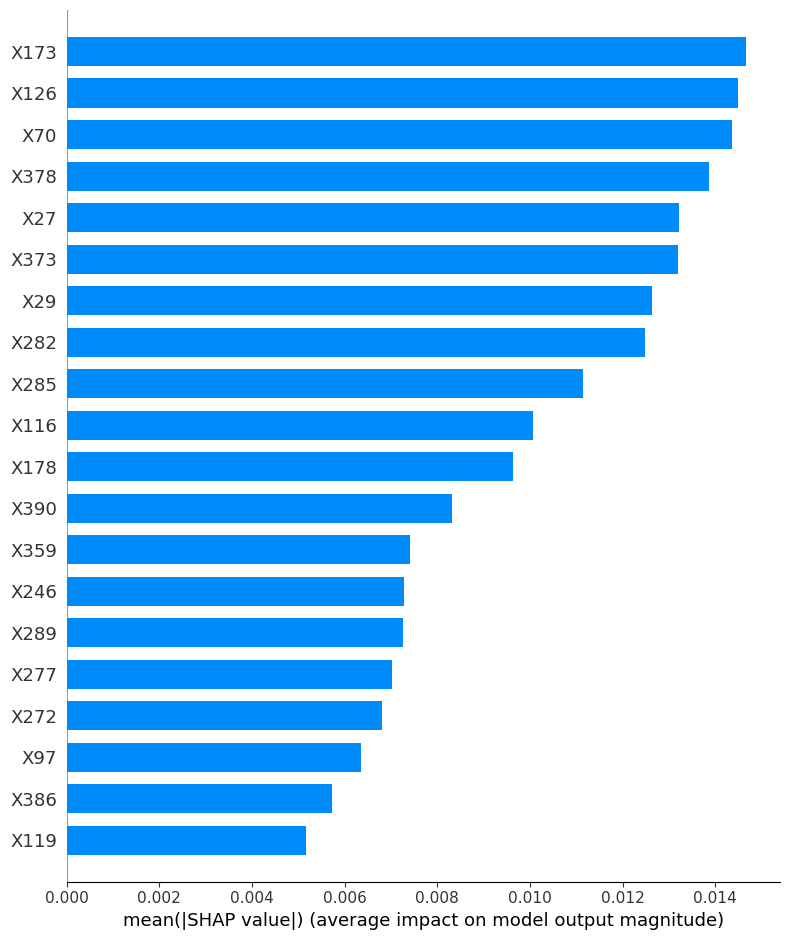

In [18]:
shap.summary_plot(shap_values_cls[:, :, 1], X_train_cls, plot_type='bar')  # 클래스 1 기준

#### Summary Plot (Scatter) - 클래스별

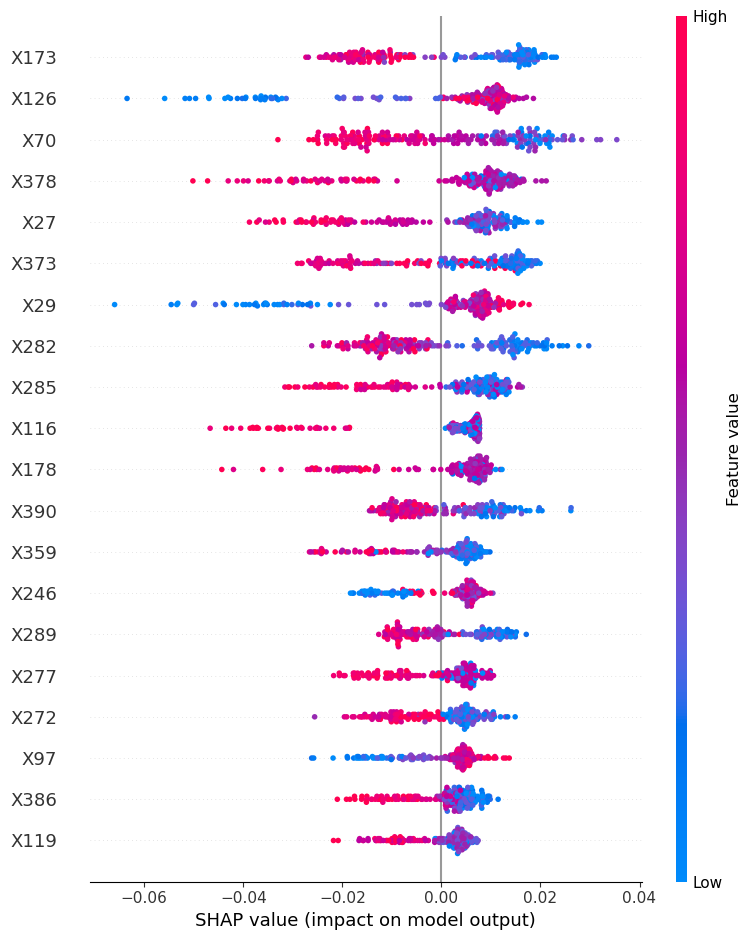

In [19]:
shap.summary_plot(shap_values_cls[:, :, 0], X_train_cls) # 클래스 = -1

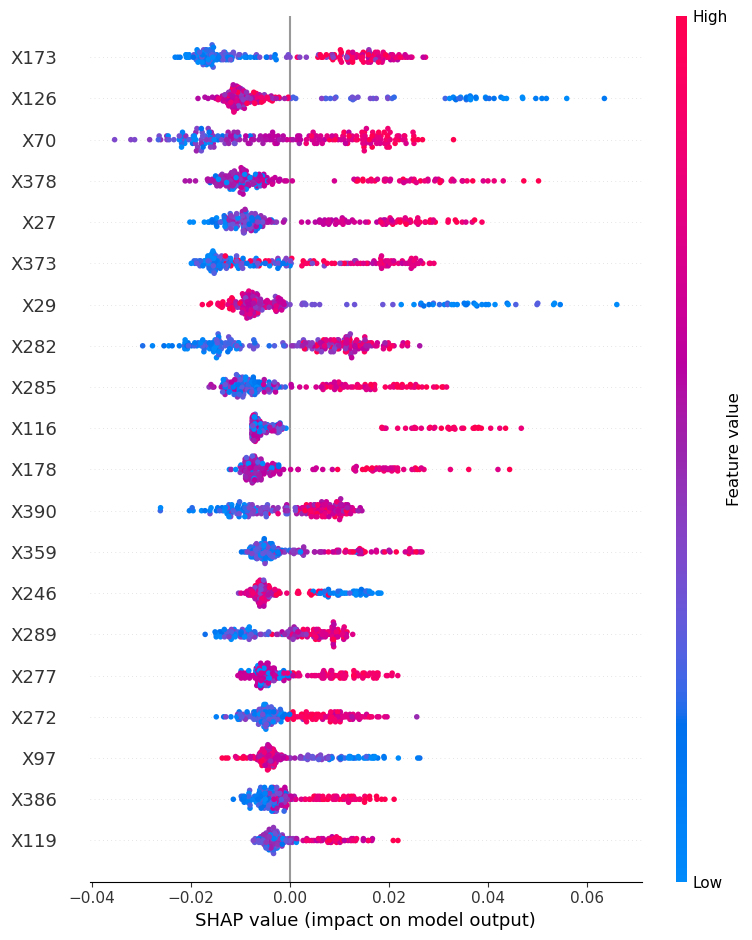

In [20]:
# 변수 중요도 순서는 같은데 부호가 반대 방향임

shap.summary_plot(shap_values_cls[:, :, 1], X_train_cls) # 클래스 = 1

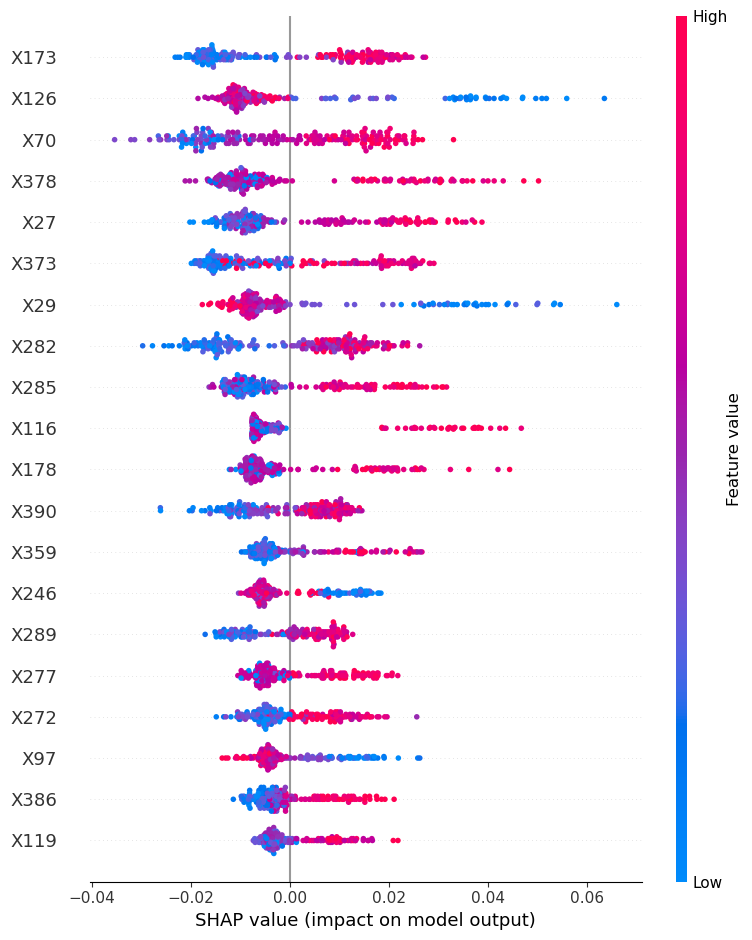

In [21]:
shap.summary_plot(shap_values_cls[:, :, 1], X_train_cls)

#### Force Plot (개별 데이터)

In [22]:
# 15번 데이터의 실제(정답) 클래스 확인
Y_train_cls.iloc[15]

np.int64(-1)

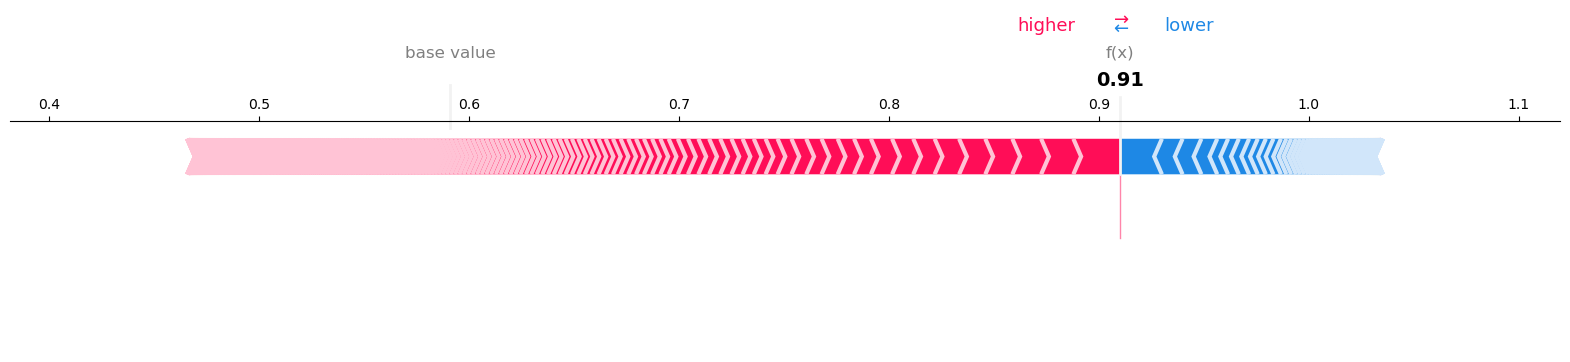

In [23]:
# 15번 데이터를 클래스 -1로 예측하는 데 각 feature가 어떻게 기여했는지 시각화

# expected_value[0]: 클래스 -1에 대한 기준값(base value)
# shap_values_cls[15, :, 0]: 15번 데이터의, 클래스 -1에 대한 각 feature별 SHAP value
# X_train_cls.iloc[15]: 15번 데이터의 실제 feature 값들 

shap.force_plot(
    explainer_cls.expected_value[0],
    shap_values_cls[15, :, 0],
    X_train_cls.iloc[15],
    matplotlib=True
)

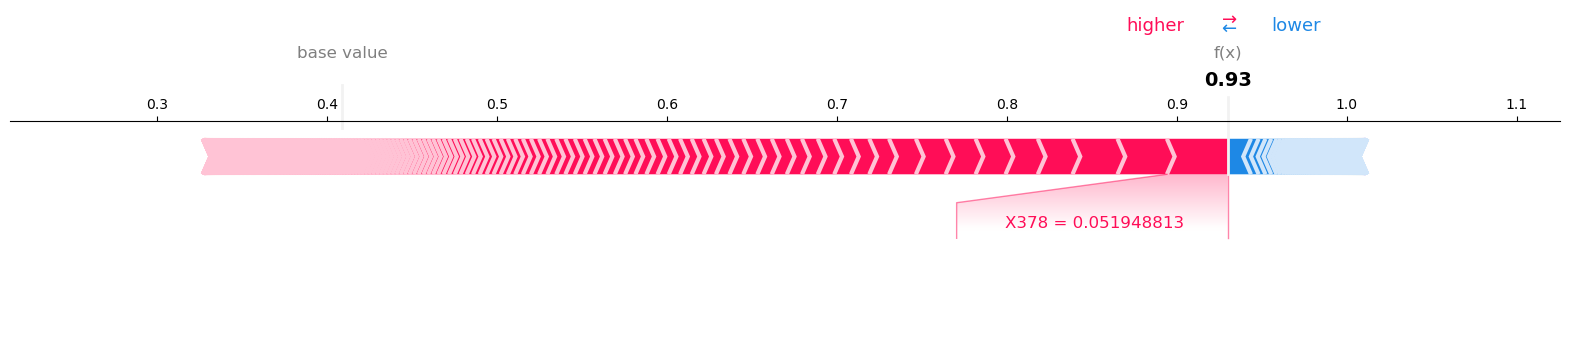

In [24]:
# 40번 데이터를 클래스 1로 예측하는 데 각 feature가 어떻게 기여했는지 시각화

# expected_value[1]: 클래스 1에 대한 기준값(base value)
# shap_values_cls[40, :, 1]: 40번 데이터의, 클래스 1에 대한 각 feature별 SHAP value
# X_train_cls.iloc[40]: 40번 데이터의 실제 feature 값들

shap.force_plot(
    explainer_cls.expected_value[1],
    shap_values_cls[40, :, 1],
    X_train_cls.iloc[40],
    matplotlib=True
)

#### Dependence Plot

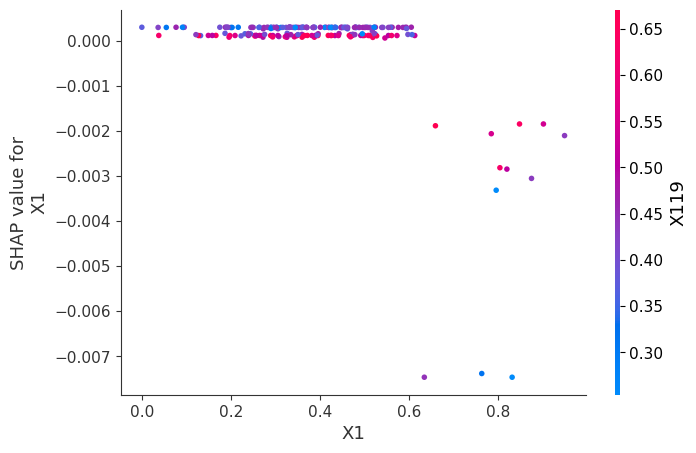

In [25]:
# "X1" feature 값에 따라, 클래스 -1에 대한 SHAP value가 어떻게 변하는지 시각화
# x축: X1의 실제 값, y축: X1의 클래스 -1 기준 SHAP value (예측에 미친 영향)
# 자동으로 X1과 가장 상호작용이 큰 feature를 색상으로 표시

shap.dependence_plot(
    "X1",
    shap_values_cls[:, :, 0],
    X_train_cls
)

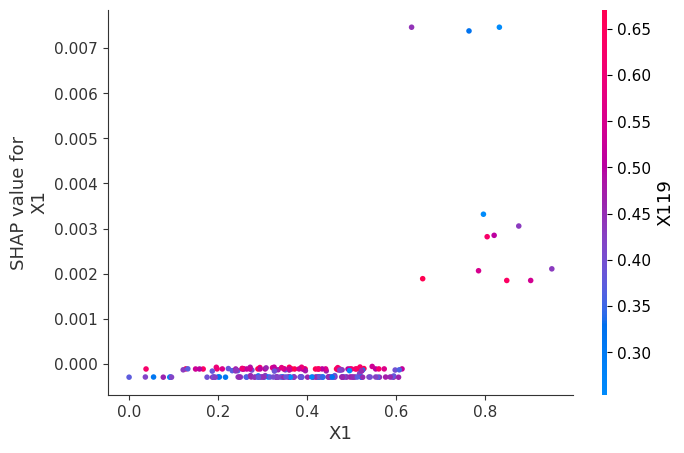

In [26]:
# "X1" feature 값에 따라, 클래스 1에 대한 SHAP value가 어떻게 변하는지 시각화
# x축: X1의 실제 값, y축: X1의 클래스 1 기준 SHAP value (예측에 미친 영향)
# 자동으로 X1과 가장 상호작용이 큰 feature를 색상으로 표시

shap.dependence_plot(
    "X1",
    shap_values_cls[:, :, 1],
    X_train_cls
)

---

## 4) Vibe Coding 실습

**[과제 1]** 

지수는 Random Forest의 Feature Importance와 SHAP Value가 모두 변수의 중요도를 설명하는 방법이라는 것을 배웠습니다.

AI와 함께 Random Forest (회귀/분류)의 feature_importances_와 SHAP Summary Plot 결과를 비교해 보세요.

두 방법에서 중요하게 평가된 변수가 얼마나 비슷한지 확인하고 순위가 다른 변수는 왜 차이가 발생했는지 AI와 토의하여 해석해 보세요.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

def compare_rf_shap(model, X, shap_values, feature_names=None, top_n=15):
    """
    RF feature_importances_ vs SHAP mean(|value|) 비교
    
    Parameters
    ----------
    model : 학습된 RandomForest 모델
    X : SHAP 계산에 사용한 DataFrame
    shap_values : TreeExplainer.shap_values() 결과
                  - 회귀: (n_samples, n_features)
                  - 분류: (n_samples, n_features) 또는 (n_samples, n_features, n_classes)
    """
    if feature_names is None:
        feature_names = X.columns.tolist()

    # 분류 3차원이면 클래스별 평균 절대 SHAP 사용
    shap_arr = np.array(shap_values)
    if shap_arr.ndim == 3:
        shap_importance = np.abs(shap_arr).mean(axis=(0, 2))
    else:
        shap_importance = np.abs(shap_arr).mean(axis=0)

    rf_importance = model.feature_importances_

    # 0~1 정규화 (스케일 차이 제거)
    rf_norm = rf_importance / rf_importance.sum()
    shap_norm = shap_importance / shap_importance.sum()

    df = pd.DataFrame({
        "feature": feature_names,
        "rf_importance": rf_importance,
        "shap_importance": shap_importance,
        "rf_norm": rf_norm,
        "shap_norm": shap_norm,
    })

    df["rf_rank"] = df["rf_importance"].rank(ascending=False, method="min").astype(int)
    df["shap_rank"] = df["shap_importance"].rank(ascending=False, method="min").astype(int)
    df["rank_diff"] = (df["rf_rank"] - df["shap_rank"]).abs()
    df["norm_diff"] = (df["rf_norm"] - df["shap_norm"]).abs()

    # 순위 유사도
    rho, p_value = spearmanr(df["rf_rank"], df["shap_rank"])

    # 정렬: SHAP 순위 기준
    df_sorted = df.sort_values("shap_rank").reset_index(drop=True)

    print("=" * 60)
    print(f"Spearman 순위 상관계수: {rho:.3f} (p={p_value:.4f})")
    print("  → 1에 가까울수록 두 방법의 순위가 비슷함")
    print("=" * 60)

    return df_sorted, rho

def plot_rf_shap_comparison(df, title="", top_n=15):
    """나란히 막대 그래프 + 산점도"""
    top = df.nsmallest(top_n, "shap_rank").sort_values("rf_rank")

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # 1) RF vs SHAP 막대 비교
    x = np.arange(len(top))
    w = 0.35
    axes[0].barh(x - w/2, top["rf_norm"], w, label="RF importance", color="steelblue")
    axes[0].barh(x + w/2, top["shap_norm"], w, label="SHAP mean|value|", color="coral")
    axes[0].set_yticks(x)
    axes[0].set_yticklabels(top["feature"])
    axes[0].invert_yaxis()
    axes[0].set_xlabel("정규화 중요도")
    axes[0].set_title(f"Top {top_n} 변수 비교")
    axes[0].legend()

    # 2) 순위 산점도
    axes[1].scatter(df["rf_rank"], df["shap_rank"], alpha=0.5, s=30)
    lim = max(df["rf_rank"].max(), df["shap_rank"].max()) + 1
    axes[1].plot([1, lim], [1, lim], "r--", label="순위 일치선")
    axes[1].set_xlabel("RF 순위")
    axes[1].set_ylabel("SHAP 순위")
    axes[1].set_title("순위 산점도")
    axes[1].legend()

    # 3) 순위 차이 큰 변수
    big_diff = df.nlargest(min(10, len(df)), "rank_diff")
    axes[2].barh(big_diff["feature"], big_diff["rank_diff"], color="gray")
    axes[2].set_xlabel("순위 차이 |RF - SHAP|")
    axes[2].set_title("순위 차이가 큰 변수")
    axes[2].invert_yaxis()

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

[회귀] RF Top 10
X10    0.193025
X3     0.141376
X46    0.089514
X26    0.050647
X33    0.034804
X2     0.033480
X25    0.028282
X37    0.026450
X15    0.022193
X58    0.015704
dtype: float64


C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\2535848278.py:10: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\2535848278.py:10: UserWarning: Glyph 44480 (\N{HANGUL SYLLABLE GWI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44480 (\N{HANGUL SYLLABLE GWI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


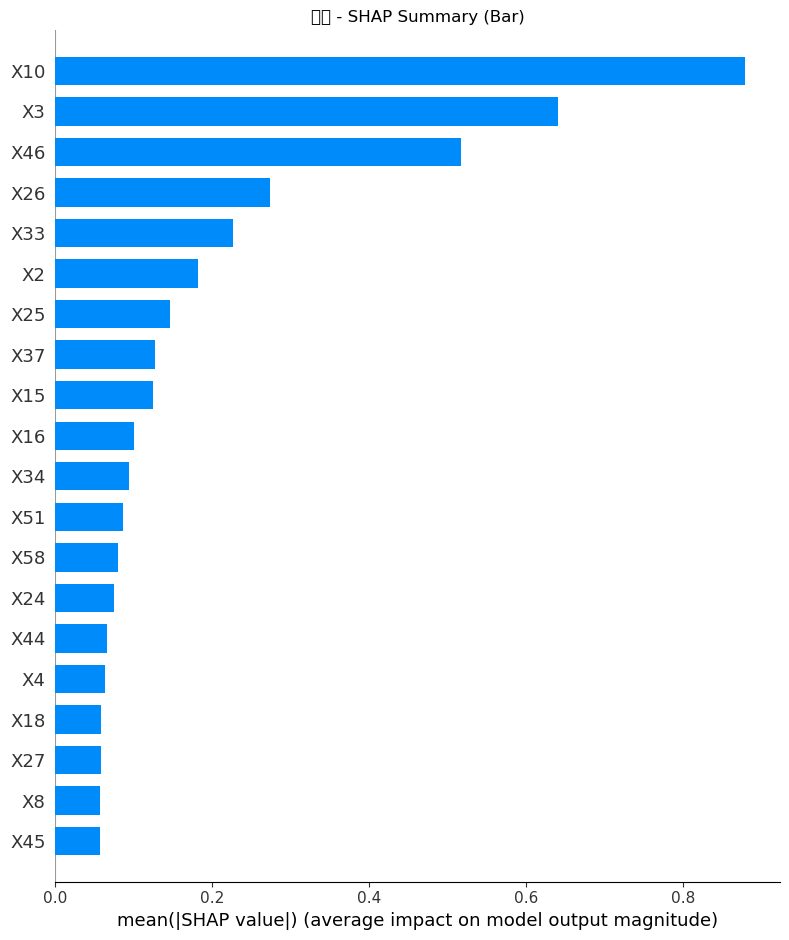

Spearman 순위 상관계수: 0.950 (p=0.0000)
  → 1에 가까울수록 두 방법의 순위가 비슷함


,feature,rf_rank,shap_rank,rank_diff,rf_norm,shap_norm,norm_diff
0,X10,1,1,0,0.193025,0.177300,0.015725
1,X3,2,2,0,0.141376,0.129213,0.012164
2,X46,3,3,0,0.089514,0.104134,0.014621
3,X26,4,4,0,0.050647,0.055165,0.004518
4,X33,5,5,0,0.034804,0.045730,0.010926
5,X2,6,6,0,0.033480,0.036682,0.003201
6,X25,7,7,0,0.028282,0.029568,0.001287
7,X37,8,8,0,0.026450,0.025662,0.000789
8,X15,9,9,0,0.022193,0.025024,0.002831
9,X16,12,10,2,0.014284,0.020329,0.006045


C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from fon

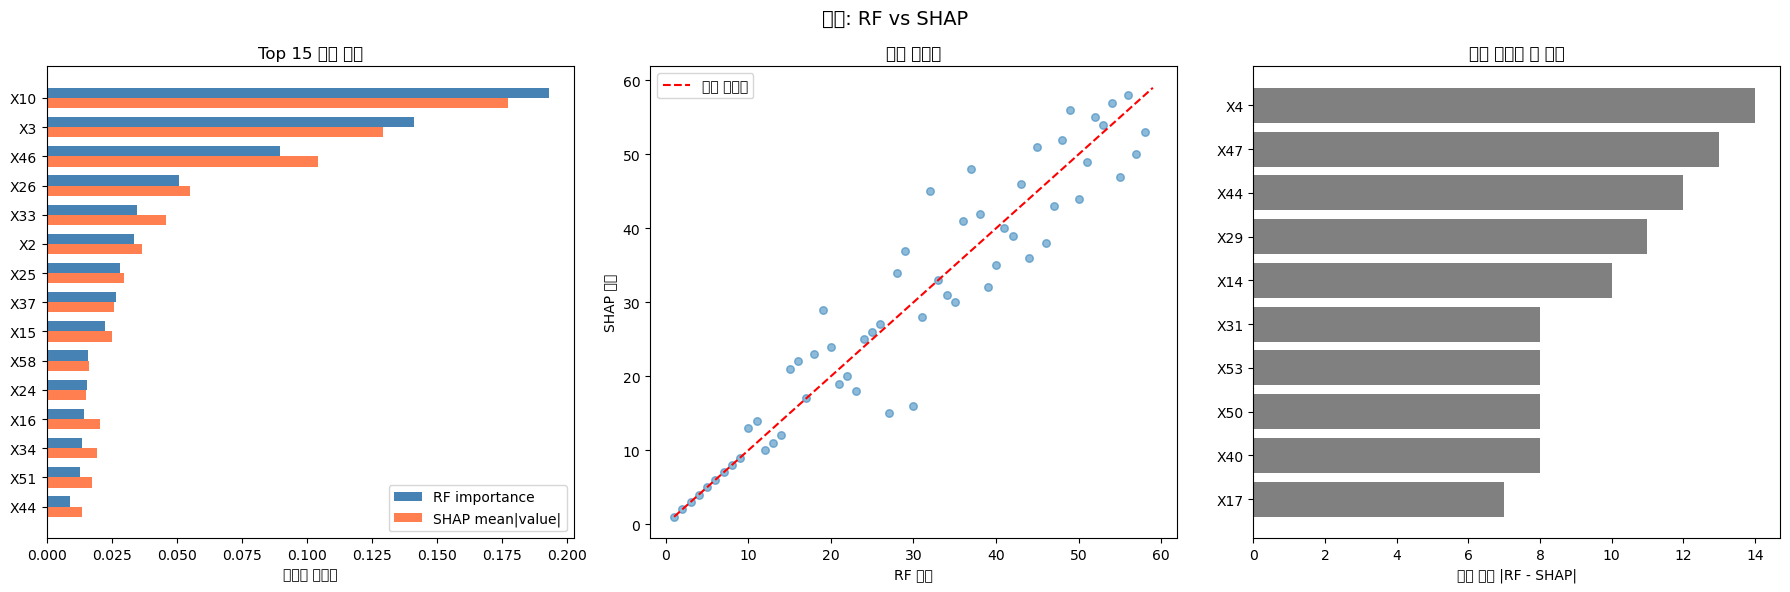

In [28]:
# --- 1) RF feature_importances_ ---
rf_imp_reg = pd.Series(rf_reg.feature_importances_, index=X_train_reg.columns)\
               .sort_values(ascending=False)
print("[회귀] RF Top 10")
print(rf_imp_reg.head(10))

# --- 2) SHAP summary plot (bar) ---
shap.summary_plot(shap_values_reg, X_train_reg, plot_type="bar", show=False)
plt.title("회귀 - SHAP Summary (Bar)")
plt.tight_layout()
plt.show()

# --- 3) 수치 비교 ---
df_reg, rho_reg = compare_rf_shap(
    rf_reg, X_train_reg, shap_values_reg, top_n=15
)
display(df_reg[["feature", "rf_rank", "shap_rank", "rank_diff",
                "rf_norm", "shap_norm", "norm_diff"]].head(15))

plot_rf_shap_comparison(df_reg, title="회귀: RF vs SHAP", top_n=15)

[분류] RF Top 10
X373    0.024285
X126    0.022421
X70     0.021257
X29     0.021031
X378    0.019221
X27     0.018447
X282    0.017265
X173    0.016975
X277    0.014767
X285    0.014313
dtype: float64


C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\2433557580.py:13: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\2433557580.py:13: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\2433557580.py:13: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\2433557580.py:13: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\2433557580.py:13: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing 

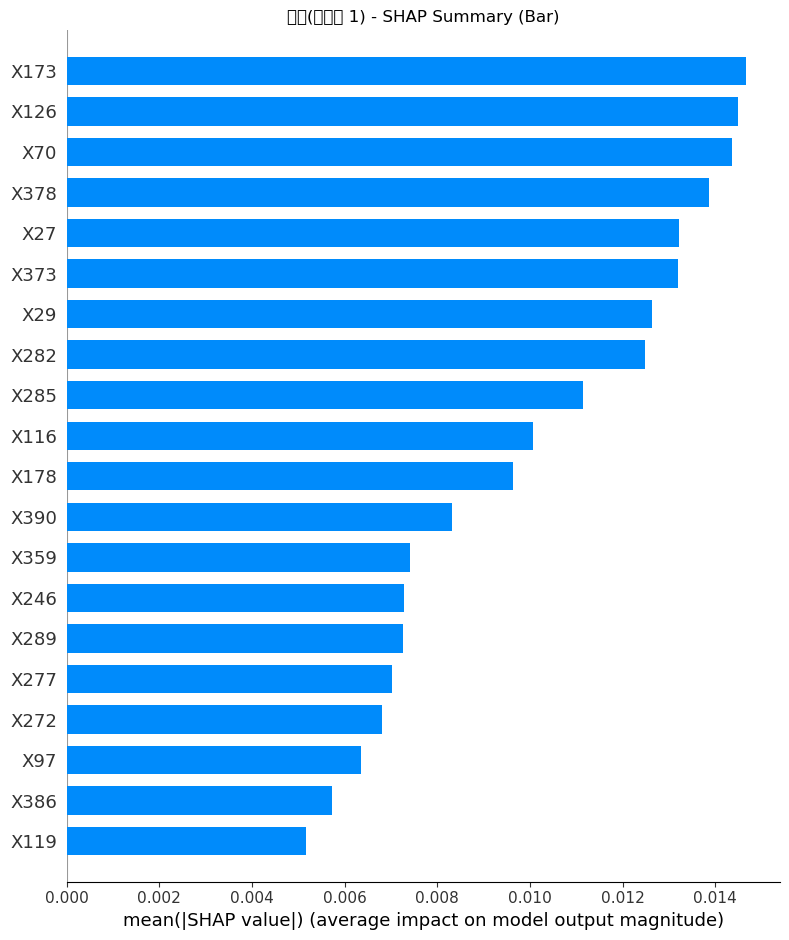

Spearman 순위 상관계수: 0.963 (p=0.0000)
  → 1에 가까울수록 두 방법의 순위가 비슷함


,feature,rf_rank,shap_rank,rank_diff,rf_norm,shap_norm,norm_diff
0,X173,8,1,7,0.016975,0.023864,0.006889
1,X126,2,2,0,0.022421,0.023591,0.001170
2,X70,3,3,0,0.021257,0.023363,0.002106
3,X378,5,4,1,0.019221,0.022574,0.003353
4,X27,6,5,1,0.018447,0.021496,0.003049
5,X373,1,6,5,0.024285,0.021486,0.002798
6,X29,4,7,3,0.021031,0.020566,0.000465
7,X282,7,8,1,0.017265,0.020304,0.003039
8,X285,10,9,1,0.014313,0.018132,0.003819
9,X116,12,10,2,0.013535,0.016374,0.002839


C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9888\1482260921.py:95: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from fon

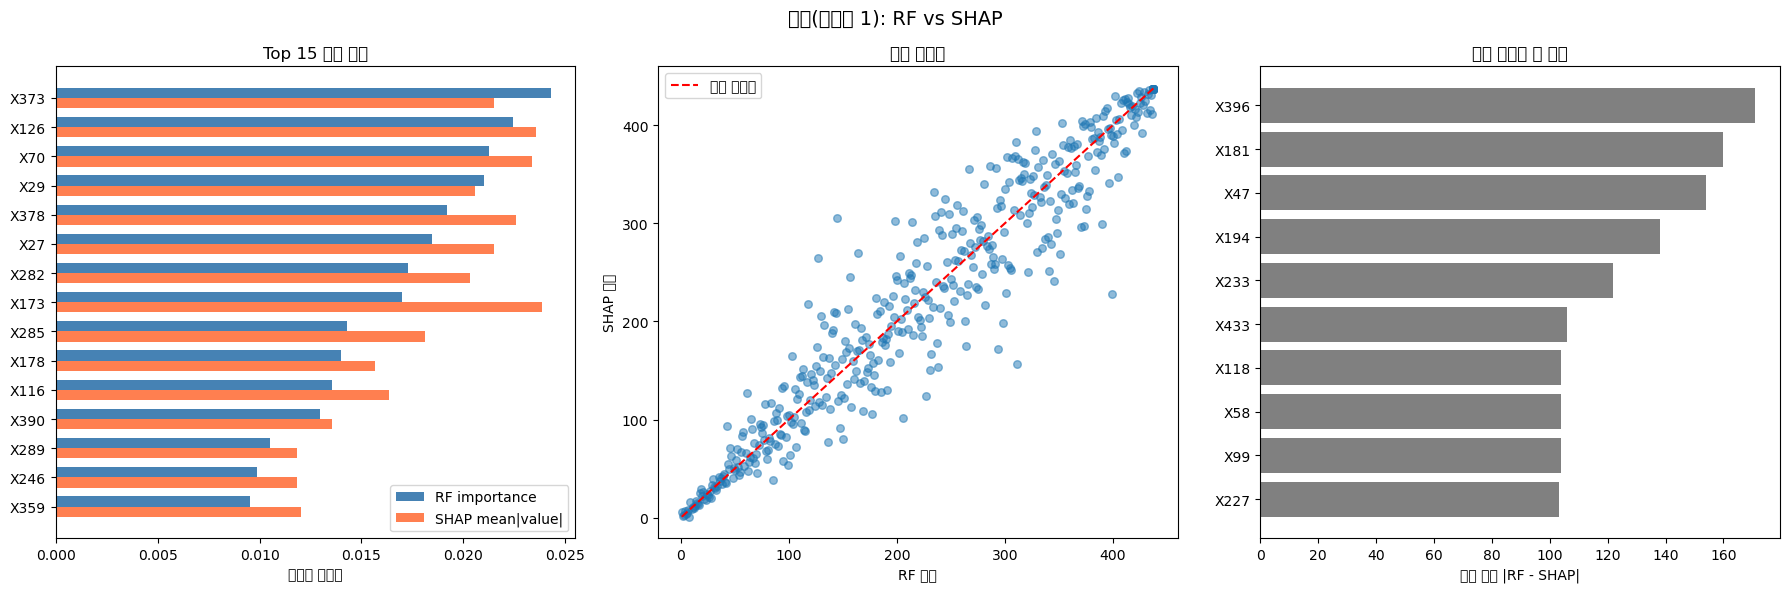

In [29]:
# 클래스 1 기준 (노트북과 동일)
shap_cls1 = shap_values_cls[:, :, 1]

# --- 1) RF importance ---
rf_imp_cls = pd.Series(rf_cls.feature_importances_, index=X_train_cls.columns)\
               .sort_values(ascending=False)
print("[분류] RF Top 10")
print(rf_imp_cls.head(10))

# --- 2) SHAP summary plot ---
shap.summary_plot(shap_cls1, X_train_cls, plot_type="bar", show=False)
plt.title("분류(클래스 1) - SHAP Summary (Bar)")
plt.tight_layout()
plt.show()

# --- 3) 수치 비교 ---
df_cls, rho_cls = compare_rf_shap(
    rf_cls, X_train_cls, shap_cls1, top_n=15
)
display(df_cls[["feature", "rf_rank", "shap_rank", "rank_diff",
                "rf_norm", "shap_norm", "norm_diff"]].head(15))

plot_rf_shap_comparison(df_cls, title="분류(클래스 1): RF vs SHAP", top_n=15)

In [31]:
def analyze_rank_differences(df, X, shap_values, rank_threshold=5, top_k=5):
    """
    RF와 SHAP 순위 차이가 큰 변수의 원인 후보를 정리
  rank_threshold: 이 값 이상 차이나는 변수만 분석
    """
    if np.array(shap_values).ndim == 3:
        shap_arr = np.abs(np.array(shap_values)).mean(axis=(0, 2))
    else:
        shap_arr = np.abs(np.array(shap_values)).mean(axis=0)

    diff_vars = df[df["rank_diff"] >= rank_threshold].sort_values(
        "rank_diff", ascending=False
    ).head(top_k)

    print(f"\n순위 차이 >= {rank_threshold} 인 변수 ({len(diff_vars)}개)")
    print("=" * 70)

    for _, row in diff_vars.iterrows():
        feat = row["feature"]
        idx = list(X.columns).index(feat)

        # SHAP 방향성: 양/음 기여 비율
        if np.array(shap_values).ndim == 3:
            raw_shap = np.array(shap_values)[:, idx, :].mean(axis=1)  # 클래스 평균
        else:
            raw_shap = np.array(shap_values)[:, idx]

        pos_ratio = (raw_shap > 0).mean()
        mean_shap = raw_shap.mean()

        # 다른 상위 변수와의 상관 (다중공선성 여부)
        top_feats = df.nsmallest(5, "shap_rank")["feature"].tolist()
        corr_with_top = X[feat].corr(X[top_feats].mean(axis=1))

        # 해석 태그
        reasons = []
        if row["rf_rank"] > row["shap_rank"]:
            reasons.append("SHAP이 RF보다 더 중요하게 평가")
            if abs(mean_shap) < 0.01 and shap_arr[idx] > 0.01:
                reasons.append("방향은 상쇄되지만 절대 기여는 큼 (양/음 혼재)")
        else:
            reasons.append("RF가 SHAP보다 더 중요하게 평가")
            if corr_with_top > 0.7:
                reasons.append("다른 핵심 변수와 상관 높음 → RF에서 분할 기여가 분산됨")

        if 0.3 < pos_ratio < 0.7:
            reasons.append(f"SHAP 방향 혼재 (양성 비율 {pos_ratio:.0%})")

        print(f"\n[{feat}]")
        print(f"  RF 순위: {int(row['rf_rank'])}  |  SHAP 순위: {int(row['shap_rank'])}  |  차이: {int(row['rank_diff'])}")
        print(f"  RF norm: {row['rf_norm']:.4f}  |  SHAP norm: {row['shap_norm']:.4f}")
        print(f"  SHAP 평균 부호: {mean_shap:+.4f}  |  양성 기여 비율: {pos_ratio:.0%}")
        print(f"  상위 변수들과 상관: {corr_with_top:.3f}")
        print(f"  → 가능한 원인: {' / '.join(reasons)}")

# 회귀
analyze_rank_differences(df_reg, X_train_reg, shap_values_reg, rank_threshold=10)

# 분류
analyze_rank_differences(df_cls, X_train_cls, shap_cls1, rank_threshold=10)


순위 차이 >= 10 인 변수 (5개)

[X4]
  RF 순위: 30  |  SHAP 순위: 16  |  차이: 14
  RF norm: 0.0079  |  SHAP norm: 0.0128
  SHAP 평균 부호: -0.0032  |  양성 기여 비율: 41%
  상위 변수들과 상관: 0.134
  → 가능한 원인: SHAP이 RF보다 더 중요하게 평가 / 방향은 상쇄되지만 절대 기여는 큼 (양/음 혼재) / SHAP 방향 혼재 (양성 비율 41%)

[X47]
  RF 순위: 32  |  SHAP 순위: 45  |  차이: 13
  RF norm: 0.0076  |  SHAP norm: 0.0041
  SHAP 평균 부호: +0.0043  |  양성 기여 비율: 52%
  상위 변수들과 상관: -0.490
  → 가능한 원인: RF가 SHAP보다 더 중요하게 평가 / SHAP 방향 혼재 (양성 비율 52%)

[X44]
  RF 순위: 27  |  SHAP 순위: 15  |  차이: 12
  RF norm: 0.0088  |  SHAP norm: 0.0133
  SHAP 평균 부호: +0.0043  |  양성 기여 비율: 55%
  상위 변수들과 상관: -0.133
  → 가능한 원인: SHAP이 RF보다 더 중요하게 평가 / 방향은 상쇄되지만 절대 기여는 큼 (양/음 혼재) / SHAP 방향 혼재 (양성 비율 55%)

[X29]
  RF 순위: 37  |  SHAP 순위: 48  |  차이: 11
  RF norm: 0.0064  |  SHAP norm: 0.0034
  SHAP 평균 부호: -0.0087  |  양성 기여 비율: 33%
  상위 변수들과 상관: 0.339
  → 가능한 원인: RF가 SHAP보다 더 중요하게 평가 / SHAP 방향 혼재 (양성 비율 33%)

[X14]
  RF 순위: 19  |  SHAP 순위: 29  |  차이: 10
  RF norm: 0.0105  |  SHAP norm: 0.0077
  SHAP 평균 부호: 